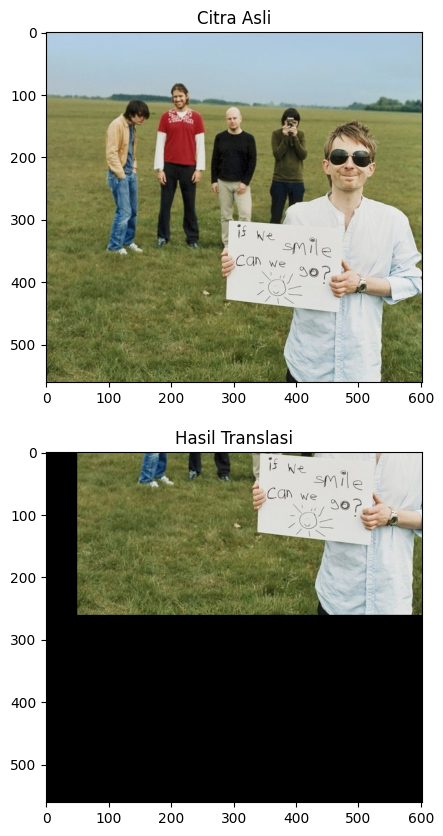

In [16]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def Translasi(image, shiftX, shiftY):

    imgTranslasi = np.roll(image, shift=shiftY, axis=0)  # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1)  # Geser horizontal

    # Mengisi bagian yang kosong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0  # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0  # Bagian bawah jika geser ke atas

    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0  # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0  # Bagian kanan jika geser ke kiri

    return imgTranslasi


image = img.imread("/content/Radiohead.jpg")

imgResult = Translasi(image, shiftX=50, shiftY=-300)

plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(2, 1, 2)
plt.imshow(imgResult)
plt.title("Hasil Translasi")

plt.show()

/tmp/ipykernel_1463/4294516594.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread(path)


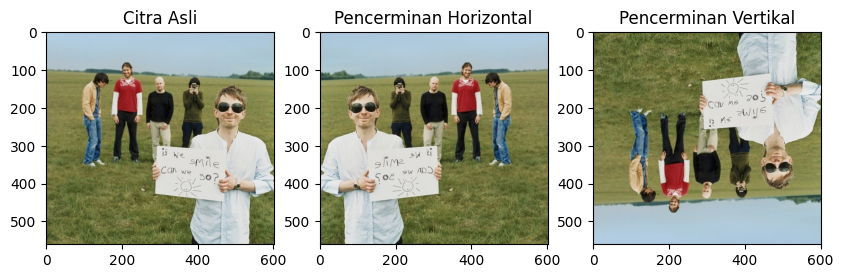

In [17]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

path = '/content/Radiohead.jpg'
image = img.imread(path)

height, width = image.shape[:2]

horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

for y in range(height):
    for x in range(width):
        vertical[y, x] = image[height - 1 - y, x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(1, 3, 2)
plt.imshow(horizontal)
plt.title("Pencerminan Horizontal")

plt.subplot(1, 3, 3)
plt.imshow(vertical)
plt.title("Pencerminan Vertikal")

plt.show()

/tmp/ipykernel_1463/952503568.py:33: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/Radiohead.jpg')


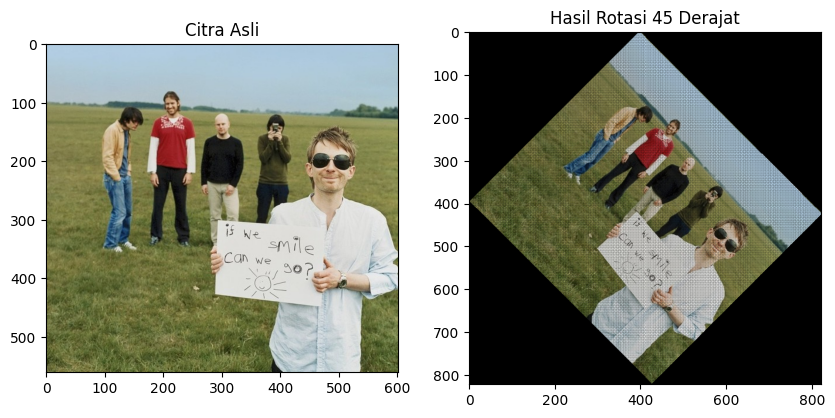

In [18]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))

    outputImage = np.zeros(
        (max_dim, max_dim, 3),
        dtype=image.dtype
    )

    centerY, centerX = max_dim // 2, max_dim // 2

    for y in range(-height // 2, height // 2):
        for x in range(-width // 2, width // 2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[
                    y + height // 2,
                    x + width // 2
                ]

    return outputImage


image = img.imread('/content/Radiohead.jpg')

rotated_image = rotateImage(image, 45)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)
plt.title("Hasil Rotasi 45 Derajat")

plt.show()

/tmp/ipykernel_1463/4124818273.py:30: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/Radiohead.jpg')


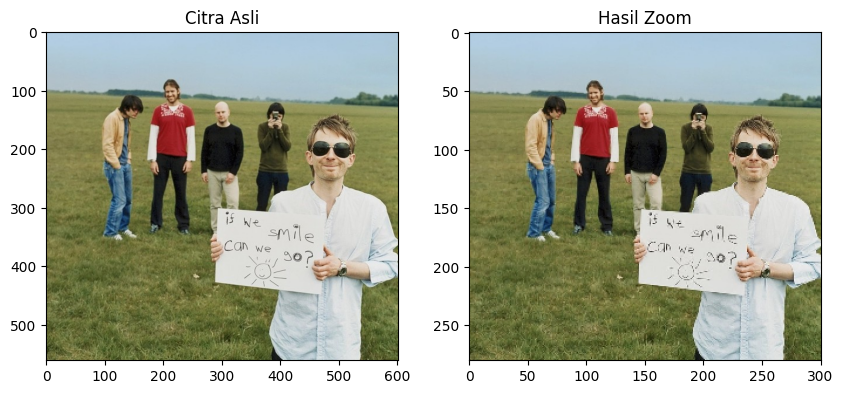

In [19]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

def zoomPlus(image, factor):
    height, width = image.shape[:2]

    new_height = int(height / factor)
    new_width = int(width / factor)

    imgZoom = np.zeros(
        (new_height, new_width, 3),
        dtype=image.dtype
    )

    for y in range(new_height):
        for x in range(new_width):

            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom


image = img.imread('/content/Radiohead.jpg')

skala = 2.0

imgZoom = zoomPlus(image, skala)

img.imwrite("D:\\z.jpg", imgZoom)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(1, 2, 2)
plt.imshow(imgZoom)
plt.title("Hasil Zoom")

plt.show()

# 1. Mirroring untuk vertical dan horizontal dilakukan secara bersamaan

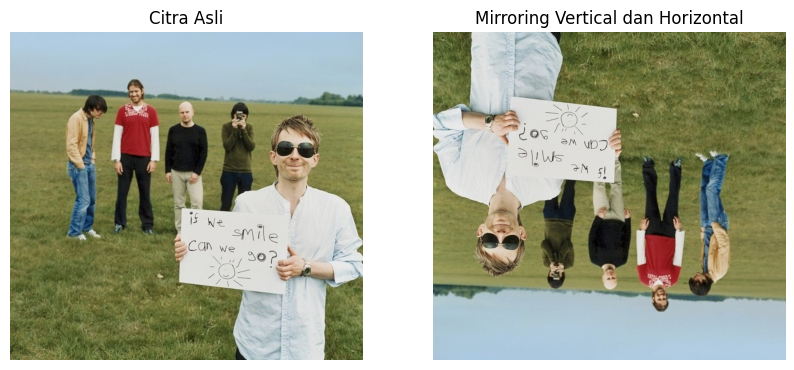

In [20]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

path = '/content/Radiohead.jpg'
image = img.imread(path)

height, width = image.shape[:2]

mirroring = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        mirroring[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mirroring)
plt.title("Mirroring Vertical dan Horizontal")
plt.axis("off")

plt.show()

#2. Rotasi Citra menggunakan pivot di titik (0,0) pojok kiri atas

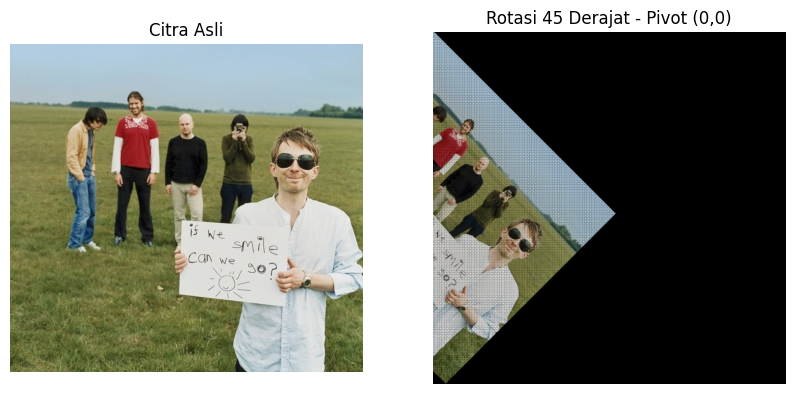

In [21]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)

    cos_deg = np.cos(radian_deg)
    sin_deg = np.sin(radian_deg)

    height, width = image.shape[:2]

    max_dim = int(np.ceil(np.sqrt(height**2 + width**2)))

    outputImage = np.zeros(
        (max_dim, max_dim, 3),
        dtype=image.dtype
    )

    for y in range(height):
        for x in range(width):

            newX = int(round(x * cos_deg - y * sin_deg))
            newY = int(round(x * sin_deg + y * cos_deg))

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y, x]

    return outputImage


image = img.imread('/content/Radiohead.jpg')

rotated_image = rotateImage(image, 45)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)
plt.title("Rotasi 45 Derajat - Pivot (0,0)")
plt.axis("off")

plt.show()

# 3. Zoom Minus untuk memperkecil gambar.

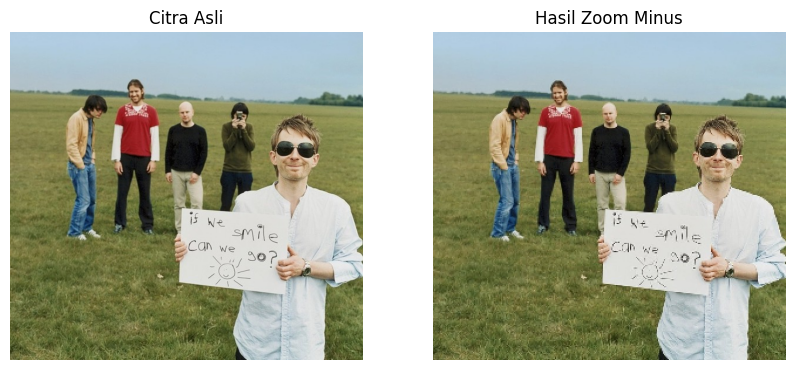

In [22]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

def zoomMinus(image, factor):
    height, width = image.shape[:2]

    new_height = int(height / factor)
    new_width = int(width / factor)

    imgZoom = np.zeros(
        (new_height, new_width, image.shape[2]),
        dtype=image.dtype
    )

    for y in range(new_height):
        for x in range(new_width):

            ori_y = int(y * factor)
            ori_x = int(x * factor)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom


image = img.imread('/content/Radiohead.jpg')

skala = 2.0

imgZoom = zoomMinus(image, skala)

img.imwrite('D:\\z_minus.jpg', imgZoom)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imgZoom)
plt.title("Hasil Zoom Minus")
plt.axis("off")

plt.show()

Nama:Deni Aditiya Saputra

NIM:20240040165

Kelas:TI24F